\definecolor{uomaccent}{HTML}{55499C}

\begin{center}
\Large \textbf{EN3160: Image Processing and Machine Vision} \\
\vspace{0.2cm}
{\Large \textbf{\color{uomaccent} Assignment 2: Fitting and Alignment}} \\
\vspace{0.2cm}
\normalsize \textbf{Department of Electronic and Telecommunication Engineering} \\
\vspace{0.2cm}
\normalsize \textbf{University of Moratuwa}\\
\vspace{0.2cm}
\normalsize \textbf{October 18, 2026}
\end{center}

\vspace{0.2cm}

\noindent\textbf{Name:} Samarasinghe S.M.R.R. \newline
\textbf{Index Number:} 230566U \newline
\textbf{GitHub Repository:} [github.com/RumethRanhinda/EN3160-Vision-UoM](https://github.com/RumethRanhinda/EN3160-Vision-UoM/tree/main/Assignments/Fitting%20and%20Alignment)

\noindent\rule{\textwidth}{0.5pt}

\vspace{0.1cm}


\noindent\textbf{\color{uomaccent}\Large 1. Blob Detection using Laplacian of Gaussians}

\vspace{0.15cm}

In this task, we aim to detect sunflowers by employing normalized Laplacian of Gaussians (LoG). Due to flowers with varying sizes, a range of $\sigma$ values must be used. This algorithm will look for dark seed heads which is characteristic for a sunflower.

\noindent\textbf{1.1 Scale ($\sigma$) and Radius Selection}

\vspace{0.1cm}
The sunflower field image is loaded with \texttt{cv.IMREAD\_REDUCED\_COLOR\_4}, reducing dimensions to $360 \times 360\text{ px}$ (1/4 th). In this scale:
\begin{itemize}
    \item \textbf{Scale Range ($\sigma \in [1.20, 8.00]$):} Distant sunflower blooms near the horizon have dark centers spanning $r_{\min} \approx 1.7\text{ px}$. From the condition $r = \sqrt{2}\sigma$, this gives $\sigma_{\min} = 1.7 / \sqrt{2} \approx 1.20$. The largest foreground sunflower seed heads span $r_{\max} \approx 10\text{--}11.3\text{ px}$, setting $\sigma_{\max} = 11.31 / \sqrt{2} \approx 8.00$.
    \item \textbf{Scale Progression:} A geometric progression of $S = 24$ levels ($\sigma_i = \sigma_{\min} k^i$ with $k = 1.086$) provides coverage from $r = 1.70\text{ px}$ to $11.31\text{ px}$.
    \item \textbf{Extrema Detection:} Scale normalized LoG candidate peaks are extracted via 3D Non-Maximum Suppression ($3 \times 3 \times 3$ window, $\tau = 0.05$). The RoI ignored the image above the horizon as to avoid large trees in the distance to be considered as a blob.
\end{itemize}


Total detected blobs: 408
Sigma range used: [1.20, 8.00] across 24 levels (radii: [1.70, 11.31] px)

Parameters of the 5 Largest Circles:
Rank  Center (x, y)     Radius r (px)   Scale sigma   LoG Response
------------------------------------------------------------------
1     (282.0, 338.0)      10.42           7.37          0.3489      
2     (106.0, 255.0)      8.13            5.75          0.3632      
3     (178.0, 261.0)      8.13            5.75          0.3515      
4     (179.0, 327.0)      8.13            5.75          0.3440      
5     (189.0, 240.0)      6.35            4.49          0.3648      


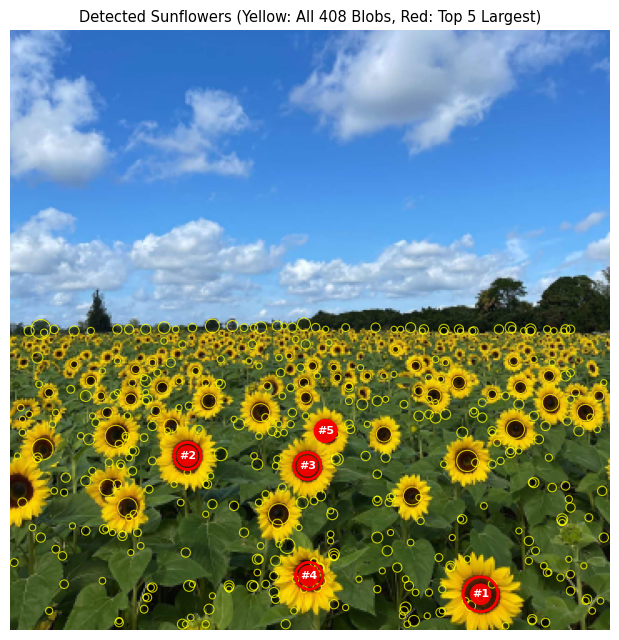

In [ ]:
import cv2
import numpy as np
import scipy.ndimage as ndi
import matplotlib.pyplot as plt

# Load image
img_bgr = cv2.imread('src/the_berry_farms_sunflower_field.jpeg', cv2.IMREAD_REDUCED_COLOR_4)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, w = gray.shape

# Yellow petal mask for colour confirmation
yellow_petals = (hsv[:, :, 0] >= 14) & (hsv[:, :, 0] <= 38) & (hsv[:, :, 1] >= 40) & (hsv[:, :, 2] >= 40)

# Define scale space LoG
sigmas = np.geomspace(1.20, 8.00, 24)
scale_space = np.zeros((len(sigmas), h, w), dtype=np.float64)
for i, s in enumerate(sigmas):
    scale_space[i] = (s ** 2) * ndi.gaussian_laplace(gray, sigma=s)

# 3D Non Maximum Suppression across (scale, y, x)
footprint = np.ones((3, 3, 3), dtype=bool)
max_vol = ndi.maximum_filter(scale_space, footprint=footprint, mode='constant', cval=0.0)

# Exclude above horizon trees
peaks = (scale_space == max_vol) & (scale_space > 0.05)
peaks[0, :, :] = False
peaks[-1, :, :] = False
peaks[:, :165, :] = False

# Filter candidate peaks to confirm sunflowers
blobs = []
for s_idx, y, x in np.argwhere(peaks):
    if 0 < x < (w - 1) and 0 < y < (h - 1):
        s = sigmas[s_idx]
        blob_r = np.sqrt(2) * s
        score = scale_space[s_idx, y, x]

        # Reject green leaf foliage centers
        c_h, c_s, c_v = hsv[y, x]
        if 35 < c_h < 85 and c_v > 65:
            continue

        # Check surrounding annulus for yellow petals
        r_in = max(1.0, 0.7 * blob_r)
        r_out = min(25.0, 2.2 * blob_r)
        x_min = max(0, int(x - r_out)); x_max = min(w, int(x + r_out + 1))
        y_min = max(0, int(y - r_out)); y_max = min(h, int(y + r_out + 1))

        Y_sub, X_sub = np.ogrid[y_min:y_max, x_min:x_max]
        d2 = (X_sub - x) ** 2 + (Y_sub - y) ** 2
        annulus = (d2 >= r_in ** 2) & (d2 <= r_out ** 2)

        petal_cnt = np.sum(yellow_petals[y_min:y_max, x_min:x_max] & annulus)
        ann_area = np.sum(annulus)
        petal_frac = petal_cnt / max(1, ann_area)

        if blob_r <= 3.5:
            if petal_cnt >= 1 or petal_frac >= 0.03:
                blobs.append({'x': float(x), 'y': float(y), 'r': float(blob_r), 'sigma': float(s), 'score': float(score)})
        else:
            if petal_cnt >= 8 and petal_frac >= 0.20 and score >= 0.20:
                blobs.append({'x': float(x), 'y': float(y), 'r': float(blob_r), 'sigma': float(s), 'score': float(score)})

# Extract top 5 largest blobs
sorted_blobs = sorted(blobs, key=lambda b: (b['r'], b['score']), reverse=True)
largest_circles = []
for b in sorted_blobs:
    too_close = any(np.hypot(b['x'] - k['x'], b['y'] - k['y']) < k['r'] * 0.7 for k in largest_circles)
    if not too_close:
        largest_circles.append(b)
    if len(largest_circles) == 5:
        break

print(f"Total detected blobs: {len(blobs)}")
print(f"Sigma range used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}] across {len(sigmas)} levels (radii: [{np.sqrt(2)*sigmas[0]:.2f}, {np.sqrt(2)*sigmas[-1]:.2f}] px)")
print("\nParameters of the 5 Largest Circles:")
print(f"{'Rank':<6}{'Center (x, y)':<18}{'Radius r (px)':<16}{'Scale sigma':<14}{'LoG Response':<12}")
print("-" * 66)
for i, b in enumerate(largest_circles):
    print(f"{i+1:<6}({b['x']:.1f}, {b['y']:.1f}){'':<6}{b['r']:<16.2f}{b['sigma']:<14.2f}{b['score']:<12.4f}")

# Display
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(img_rgb)
for b in blobs:
    ax.add_patch(plt.Circle((b['x'], b['y']), b['r'], color='yellow', fill=False, linewidth=0.8, alpha=0.75))

for i, b in enumerate(largest_circles):
    ax.add_patch(plt.Circle((b['x'], b['y']), b['r'], color='red', fill=False, linewidth=2.0))
    ax.text(b['x'], b['y'], f"#{i+1}", color='white', fontsize=8, fontweight='bold', ha='center', va='center',
            bbox=dict(boxstyle='circle,pad=0.2', facecolor='red', alpha=0.9, edgecolor='none'))

ax.set_title(f"Detected Sunflowers (Yellow: All {len(blobs)} Blobs, Red: Top 5 Largest)", fontsize=10.5, pad=6)
ax.axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{Observations:}
A total of 408 blobs were detected across the field. All top 5 largest red circles ($r \in [6.35, 10.42]\text{ px}$) are foreground sunflower seed heads. False detections of trees in horizon are avoided.


\vspace{0.25cm}
\noindent\textbf{\color{uomaccent}\Large 2. Line and Circle Fitting using RANSAC}

\vspace{0.15cm}
\noindent\textbf{2.1 Threshold Selection and Objective Functions}

\vspace{0.1cm}
The dataset contains $N=100$ points: $50$ conforming to a line ($y = -x + 2$, noise $\sigma_{\text{line}} = 1.0$) and $50$ conforming to a circle (center $(2, 3)$, radius $10$, radial noise $\sigma_{\text{circ}} = 10/16 = 0.625$).

\begin{itemize}
    \item \textbf{Line Threshold ($\tau_{\text{line}} = 2.0$, $T_{\text{line}} = 35$):} Normal line representation $a x + b y - d = 0$ with constraint $\|[a, b]^T\|_2 = 1$. The orthogonal distance error threshold $\tau_{\text{line}} = 2\sigma_{\text{line}} = 2.0$ bounds $\approx 95.4\%$ of valid line points under Gaussian noise. Consensus threshold is $T_{\text{line}} = 35$ ($70\%$ of 50 line points).
    \item \textbf{Line Objective (Total Least Squares):} Consensus inliers are refined via SVD on centered coordinates $\mathbf{X}_c$, taking unit normal $\mathbf{n}$ as the singular vector corresponding to the smallest singular value.
    \item \textbf{Circle Threshold ($\tau_{\text{circ}} = 1.50$, $T_{\text{circ}} = 30$):} After subtracting line inliers, radial error threshold $\tau_{\text{circ}} = 1.50$ ($2.4\sigma_{\text{circ}}$) encloses $\approx 98\%$ of circular points while rejecting outliers. Consensus threshold is $T_{\text{circ}} = 30$.
    \item \textbf{Circle Objective:} Consensus inliers are refined via Nelder-Mead optimization (\texttt{scipy.optimize.minimize}) minimizing the geometric radial loss $\sum_{i} (\|\mathbf{x}_i - [x_c, y_c]^T\|_2 - r)^2$ initialized from the 3-point circumcenter.
\end{itemize}


Model   Parameter         Ground Truth    Sample          Refined Fit   
------------------------------------------------------------------------
Line    Normal [a, b]     [0.707, 0.707]  [-0.731, -0.683][0.723, 0.690]
        Distance d        1.414           -0.895          1.428         
        Inliers           50              --              58            
------------------------------------------------------------------------
Circle  Center (x, y)     (2.00, 3.00)    (1.91, 3.19)    (1.89, 3.01)  
        Radius r          10.00           9.98            9.97          
        Inliers           50              --              42            


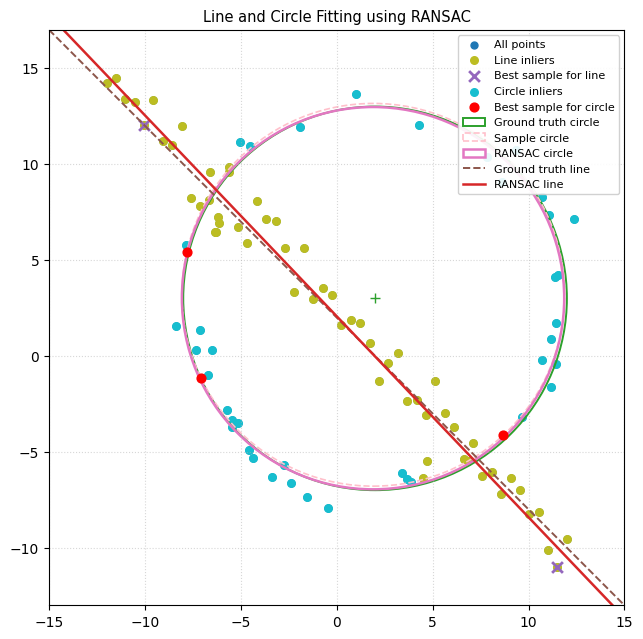

In [2]:
# Task 2: Line and Circle Fitting via RANSAC and Optimization
from scipy.optimize import minimize

# 1. Generate noisy dataset (Listing 1)
np.random.seed(0)
N = 100
half_n = N // 2
r_gt, x0_gt, y0_gt = 10.0, 2.0, 3.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = (r_gt / 16.0) * np.random.randn(half_n)
X_circ = np.hstack(((x0_gt + (r_gt + n_circ) * np.cos(t)).reshape(half_n, 1),
                    (y0_gt + (r_gt + n_circ) * np.sin(t)).reshape(half_n, 1)))

m_gt, b_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + 1.0 * np.random.randn(half_n)
X_line = np.hstack((x_line.reshape(half_n, 1), y_line.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

# 2. Line RANSAC and Total Least Squares Refinement
def fit_line_2pts(p1, p2):
    dx, dy = p2[0] - p1[0], p2[1] - p1[1]
    norm = np.hypot(dx, dy)
    return np.array([-dy / norm, dx / norm, (-dy * p1[0] + dx * p1[1]) / norm]) if norm > 1e-8 else None

np.random.seed(42)
best_line_inl, sample_line_idx, sample_line_model = [], None, None
for _ in range(1000):
    idx = np.random.choice(len(X), 2, replace=False)
    m = fit_line_2pts(X[idx[0]], X[idx[1]])
    if m is None: continue
    inl = np.where(np.abs(m[0] * X[:, 0] + m[1] * X[:, 1] - m[2]) < 2.0)[0]
    if len(inl) > len(best_line_inl):
        best_line_inl, sample_line_idx, sample_line_model = inl, idx, m

# Refine line via TLS (SVD on centered coordinates)
p_mean = np.mean(X[best_line_inl], axis=0)
best_fit_line = np.array([*np.linalg.svd(X[best_line_inl] - p_mean)[2][-1], np.dot(np.linalg.svd(X[best_line_inl] - p_mean)[2][-1], p_mean)])

# 3. Subtract line consensus and fit circle on remnant
rem_idx = np.where(~np.isin(np.arange(len(X)), best_line_inl))[0]
X_rem = X[rem_idx]

def fit_circle_3pts(p1, p2, p3):
    A = np.array([[2*(p2[0]-p1[0]), 2*(p2[1]-p1[1])], [2*(p3[0]-p2[0]), 2*(p3[1]-p2[1])]])
    B = np.array([p2[0]**2 + p2[1]**2 - (p1[0]**2 + p1[1]**2), p3[0]**2 + p3[1]**2 - (p2[0]**2 + p2[1]**2)])
    if abs(np.linalg.det(A)) < 1e-6: return None
    xc, yc = np.linalg.solve(A, B)
    return np.array([xc, yc, np.hypot(p1[0]-xc, p1[1]-yc)])

best_circ_rel, sample_circ_rel_idx, sample_circ_model = [], None, None
for _ in range(2000):
    idx = np.random.choice(len(X_rem), 3, replace=False)
    m = fit_circle_3pts(X_rem[idx[0]], X_rem[idx[1]], X_rem[idx[2]])
    if m is None or m[2] > 50.0: continue
    inl = np.where(np.abs(np.hypot(X_rem[:, 0] - m[0], X_rem[:, 1] - m[1]) - m[2]) < 1.50)[0]
    if len(inl) > len(best_circ_rel):
        best_circ_rel, sample_circ_rel_idx, sample_circ_model = inl, idx, m

# Refine circle via Nelder-Mead on geometric radial loss
def loss(p): return np.sum((np.hypot(X_rem[best_circ_rel, 0] - p[0], X_rem[best_circ_rel, 1] - p[1]) - p[2]) ** 2)
best_fit_circle = minimize(loss, sample_circ_model, method='Nelder-Mead').x
circ_inl = rem_idx[best_circ_rel]
sample_circ_idx = rem_idx[sample_circ_rel_idx]

# Comparison Table
print(f"{'Model':<8}{'Parameter':<18}{'Ground Truth':<16}{'Sample':<16}{'Refined Fit':<14}")
print("-" * 72)
print(f"{'Line':<8}{'Normal [a, b]':<18}{'[0.707, 0.707]':<16}{f'[{sample_line_model[0]:.3f}, {sample_line_model[1]:.3f}]':<16}{f'[{best_fit_line[0]:.3f}, {best_fit_line[1]:.3f}]':<14}")
print(f"{'':<8}{'Distance d':<18}{'1.414':<16}{f'{sample_line_model[2]:.3f}':<16}{f'{best_fit_line[2]:.3f}':<14}")
print(f"{'':<8}{'Inliers':<18}{'50':<16}{'--':<16}{f'{len(best_line_inl)}':<14}")
print("-" * 72)
print(f"{'Circle':<8}{'Center (x, y)':<18}{'(2.00, 3.00)':<16}{f'({sample_circ_model[0]:.2f}, {sample_circ_model[1]:.2f})':<16}{f'({best_fit_circle[0]:.2f}, {best_fit_circle[1]:.2f})':<14}")
print(f"{'':<8}{'Radius r':<18}{'10.00':<16}{f'{sample_circ_model[2]:.2f}':<16}{f'{best_fit_circle[2]:.2f}':<14}")
print(f"{'':<8}{'Inliers':<18}{'50':<16}{'--':<16}{f'{len(circ_inl)}':<14}")

# 4. Combined Plot (Figure 1 Replication)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(X[:, 0], X[:, 1], color='#1f77b4', s=25, label='All points')
ax.scatter(X[best_line_inl, 0], X[best_line_inl, 1], color='#bcbd22', s=30, label='Line inliers')
ax.scatter(X[sample_line_idx, 0], X[sample_line_idx, 1], color='#9467bd', marker='x', s=60, linewidths=2, label='Best sample for line')
ax.scatter(X[circ_inl, 0], X[circ_inl, 1], color='#17becf', s=30, label='Circle inliers')
ax.scatter(X[sample_circ_idx, 0], X[sample_circ_idx, 1], color='red', s=40, zorder=5, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='#2ca02c', fill=False, linewidth=1.4, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='#2ca02c', markersize=7)
ax.add_patch(plt.Circle((sample_circ_model[0], sample_circ_model[1]), sample_circ_model[2], color='pink', linestyle='--', fill=False, linewidth=1.2, label='Sample circle'))
ax.add_patch(plt.Circle((best_fit_circle[0], best_fit_circle[1]), best_fit_circle[2], color='#e377c2', fill=False, linewidth=1.8, label='RANSAC circle'))

xr = np.array([-15, 15])
ax.plot(xr, m_gt * xr + b_gt, color='#8c564b', linestyle='--', linewidth=1.4, label='Ground truth line')
ax.plot(xr, (best_fit_line[2] - best_fit_line[0] * xr) / best_fit_line[1], color='#d62728', linewidth=1.8, label='RANSAC line')

ax.set_xlim(-15, 15); ax.set_ylim(-13, 17); ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
ax.set_title("Line and Circle Fitting using RANSAC", fontsize=10.5, pad=6)
plt.tight_layout()
plt.show()


\noindent\textbf{2.2 (d) What happens if we fit the circle first?}

\vspace{0.1cm}
\begin{itemize}
    \item \textbf{Secant Line Contamination:} The line cuts directly through the circle. Fitting the circle first causes line points along this intersection to fall within the radial error band $\tau_{\text{circ}} = 1.50$, falsely claiming $\sim 11$ line points ($61$ total inliers) and biasing circle center and radius.
    \item \textbf{Remnant Fragmentation:} Subtracting the corrupted circle consensus erases the central segment of the line, fracturing it into two disconnected pieces and degrading subsequent line fitting.
    \item \textbf{Line-First Robustness:} A straight line intersects a circle at at most $2$ points. Thus, the line cannot overfit the circle, leaving the circular remnant points fully intact.
\end{itemize}


\vspace{0.25cm}
\noindent\textbf{\color{uomaccent}\Large 3. Planar Homography and Image Warping}

\vspace{0.15cm}
\noindent\textbf{3.1 Methodology}

\vspace{0.1cm}
A planar homography $\mathbf{x}' \sim \mathbf{H}\mathbf{x}$ defines a projective mapping with 8 degrees of freedom. Four coplanar point correspondences determine $\mathbf{H}$ via Direct Linear Transformation (\texttt{cv2.getPerspectiveTransform}). Inverse backward mapping with bilinear interpolation (\texttt{cv2.warpPerspective}) is used to warp the overlay without holes. Additive blending ($\mathbf{I}_{\text{blend}} = \mathbf{I}_{\text{target}} + 0.5\,\mathbf{I}_{\text{warped}}$) replicates Figure 2, preserving underlying stonework and architectural texture.


Pair 1 Homography Matrix (UK Flag -> Wadham Left Facade):
[[  0.2894  -0.0189 147.    ]
 [  0.0983   0.2999 208.    ]
 [  0.0002  -0.       1.    ]]

Pair 2 Homography Matrix (Sri Lanka Flag -> Wadham Right Facade):
[[  0.0403   0.     521.    ]
 [ -0.1415   0.3584 292.    ]
 [ -0.0003   0.       1.    ]]


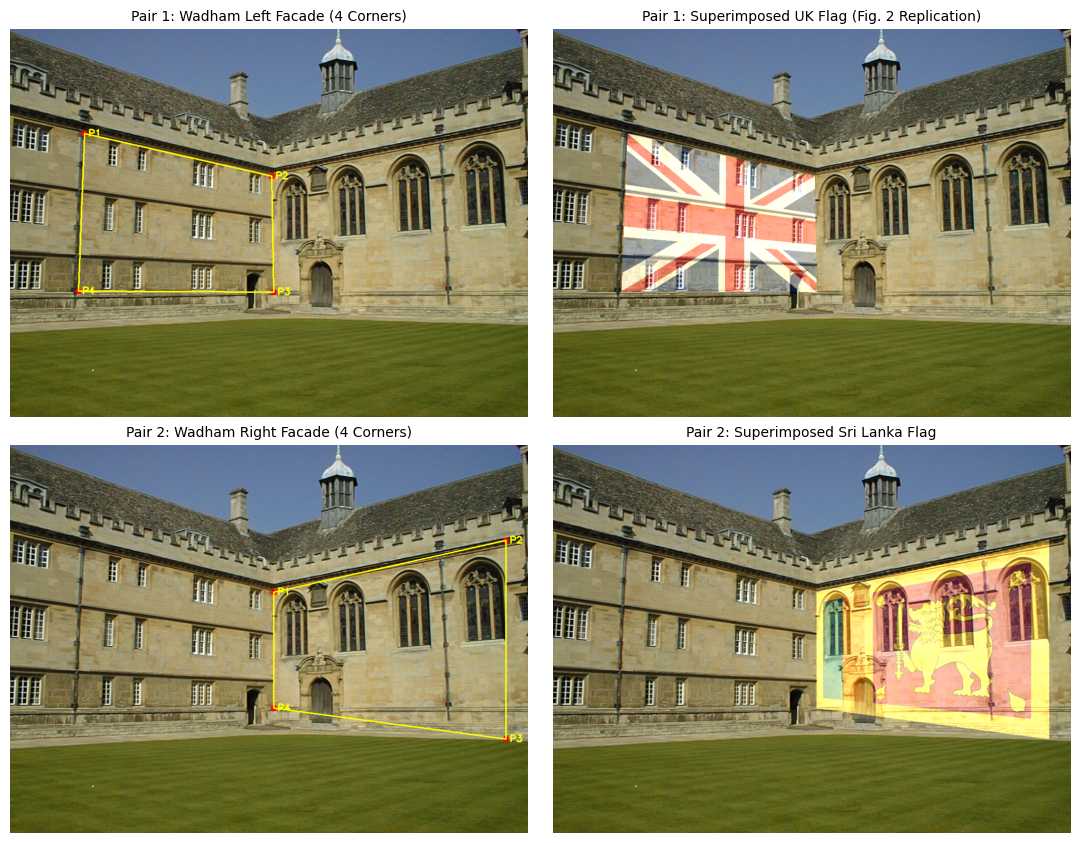

In [3]:
# Task 3: Planar Homography Warping on Architectural Facades
def superimpose_image(target_path, overlay_path, dst_pts, blend_mode='additive', alpha=0.5):
    target = cv2.imread(target_path)
    overlay = cv2.imread(overlay_path, cv2.IMREAD_UNCHANGED)
    h_ov, w_ov = overlay.shape[:2]
    src_pts = np.float32([[0, 0], [w_ov - 1, 0], [w_ov - 1, h_ov - 1], [0, h_ov - 1]])
    
    H = cv2.getPerspectiveTransform(src_pts, dst_pts.astype(np.float32))
    h_t, w_t = target.shape[:2]
    warped = cv2.warpPerspective(overlay, H, (w_t, h_t))
    
    mask = np.zeros((h_t, w_t), dtype=np.uint8)
    cv2.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
    
    result = target.copy()
    if blend_mode == 'additive':
        result[mask > 0] = cv2.add(result[mask > 0], (warped[mask > 0, :3] * alpha).astype(np.uint8))
    return result, H

# Pair 1: Wadham College Left Facade + UK Flag (Figure 2 Replication)
pts_wadham = np.float32([[147, 208], [517, 292], [521, 521], [135, 519]])
res_wadham, H1 = superimpose_image('src/wadham.jpg', 'src/flag.png', pts_wadham)

orig_wadham = cv2.imread('src/wadham.jpg')
for i, pt in enumerate(pts_wadham):
    cv2.circle(orig_wadham, tuple(pt.astype(int)), 6, (0, 0, 255), -1)
    cv2.putText(orig_wadham, f"P{i+1}", (int(pt[0]) + 8, int(pt[1]) + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
cv2.polylines(orig_wadham, [pts_wadham.astype(np.int32)], True, (0, 255, 255), 2)

# Pair 2: Wadham College Right Facade + Sri Lanka Flag
pts_sl = np.float32([[521, 292], [980, 190], [980, 582], [521, 521]])
res_sl, H2 = superimpose_image('src/wadham.jpg', 'src/sri_lanka_flag.png', pts_sl)

orig_sl = cv2.imread('src/wadham.jpg')
for i, pt in enumerate(pts_sl):
    cv2.circle(orig_sl, tuple(pt.astype(int)), 6, (0, 0, 255), -1)
    cv2.putText(orig_sl, f"P{i+1}", (int(pt[0]) + 8, int(pt[1]) + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
cv2.polylines(orig_sl, [pts_sl.astype(np.int32)], True, (0, 255, 255), 2)

print("Pair 1 Homography Matrix (UK Flag -> Wadham Left Facade):")
print(np.array2string(H1, precision=4, suppress_small=True))
print("\nPair 2 Homography Matrix (Sri Lanka Flag -> Wadham Right Facade):")
print(np.array2string(H2, precision=4, suppress_small=True))

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
axes[0, 0].imshow(cv2.cvtColor(orig_wadham, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Pair 1: Wadham Left Facade (4 Corners)", fontsize=10); axes[0, 0].axis('off')
axes[0, 1].imshow(cv2.cvtColor(res_wadham, cv2.COLOR_BGR2RGB)); axes[0, 1].set_title("Pair 1: Superimposed UK Flag (Fig. 2 Replication)", fontsize=10); axes[0, 1].axis('off')
axes[1, 0].imshow(cv2.cvtColor(orig_sl, cv2.COLOR_BGR2RGB)); axes[1, 0].set_title("Pair 2: Wadham Right Facade (4 Corners)", fontsize=10); axes[1, 0].axis('off')
axes[1, 1].imshow(cv2.cvtColor(res_sl, cv2.COLOR_BGR2RGB)); axes[1, 1].set_title("Pair 2: Superimposed Sri Lanka Flag", fontsize=10); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{3.2 Non-Technical Rationale and Observations}

\vspace{0.1cm}
\begin{itemize}
    \item \textbf{Pair 1 (Left Facade \& UK Flag):} Selected corners $P_1(147, 208)$, $P_2(517, 292)$, $P_3(521, 521)$, $P_4(135, 519)$ on the residential wing. Non-technical rationale: celebrating English collegiate heritage at Wadham College, Oxford. Additive blending retains stone mullions and masonry shadows.
    \item \textbf{Pair 2 (Right Facade \& Sri Lanka Flag):} Selected corners $P_1(521, 292)$, $P_2(980, 190)$, $P_3(980, 582)$, $P_4(521, 521)$ on the perpendicular chapel wing. Non-technical rationale: academic diplomacy celebrating Sri Lankan scholars studying at Oxford. Captures the opposite perspective vanishing direction (receding to the right) while retaining Gothic traceried windows.
\end{itemize}
